# El miedo que no baja
## Inseguridad percibida y delito registrado en Bogotá

**Bogotá DataJam Edición 5 (2026)** · Equipo #16 **The data squad**: Rafael Estiven Londoño Camacho, Brandow Brusly León Rodríguez y Samuel Esteban Riveros Cubides.

| | |
|---|---|
| **Problema público** | Bogotá registra muchos menos delitos contra el patrimonio que en 2019, pero tres de cada cuatro adultos califican la ciudad como insegura. Una política que solo mira el delito registrado no ve ni el delito que no se denuncia ni lo que forma la sensación de inseguridad. |
| **Pregunta analítica** | ¿Por qué la inseguridad percibida no baja cuando el delito registrado sí, y en qué territorios debe intervenir primero el Distrito? |
| **Hipótesis** | H1. La percepción del barrio depende más del entorno inmediato (lo que la persona ve en su cuadra y su parque) que del delito registrado en su localidad. H2. Parte de la distancia entre miedo y registro es subregistro: donde hay más miedo que delito registrado, más delito queda fuera de las cifras. H3. A igual victimización, las mujeres restringen más su vida (salir de noche) y temen más el acoso. |
| **Fuentes (7)** | SCJ (delitos de alto impacto e incidentes de la Línea 123), SDP (proyecciones de población por localidad y UPZ), SCRD (Encuesta Bienal de Cultura Ciudadana 2025), Encuesta Mundial de Valores 2024 (Datos para la Transparencia), UAESP (alumbrado), DADEP (espacio público), IDECA (límites). |
| **Método** | Integración por código de localidad con tasas por 100.000; logit ponderado con efectos marginales e intervalos por bootstrap de localidades; robustez (efectos fijos, wild cluster bootstrap); AUC fuera de muestra; Índice de Brecha de Seguridad con incertidumbre; escenarios. |

Cómo leer este notebook: cada sección corresponde a un eslabón de la trazabilidad que pide la ficha metodológica (problema → datos → metodología → resultados → recomendaciones). Toda la lógica vive en `src/` y aquí se ejecuta paso a paso; `python src/pipeline.py` produce exactamente las mismas cifras sin abrir el notebook.

## 0. Configuración y reproducibilidad

In [1]:
import sys, platform, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np, pandas as pd, statsmodels, sklearn, geopandas
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

import fuentes, limpieza as L, indicadores as I, modelos as M, pipeline as PL, figuras as F, exportar as EX
from territorio import LOCALIDADES, cod_localidad

print("Python", platform.python_version(), "| pandas", pd.__version__, "| statsmodels", statsmodels.__version__,
      "| scikit-learn", sklearn.__version__, "| geopandas", geopandas.__version__)
N_BOOT = 300   # réplicas bootstrap (las semillas están fijas en cada función: resultados idénticos en cada corrida)

Python 3.11.15 | pandas 3.0.6 | statsmodels 0.15.0 | scikit-learn 1.9.1 | geopandas 1.2.0


## 1. Auditoría de datos: lo ideal frente a lo disponible

Antes de modelar auditamos qué existe realmente (paso 2 de la metodología DIPEA). Cada variable ideal tiene su proxy justificado y su limitación explícita.

| Variable ideal | Lo disponible | Granularidad | Limitación y manejo |
|---|---|---|---|
| Delito ocurrido por barrio y mes | Delitos de alto impacto por localidad, SCJ, enero-agosto 2018-2026 | Localidad | Registro = denuncias. Se contrasta con victimización (EMV) para estimar la cifra oculta |
| Percepción de seguridad frecuente por UPL | Encuesta Bienal de Cultura Ciudadana 2025 (microdatos con factor de expansión) | Persona, representativa por localidad | Un solo año. Para el seguimiento se propone la Encuesta Distrital de Percepción (bimestral, por UPL) |
| Victimización por localidad | Encuesta Mundial de Valores ola 8, 2024 | Persona, 96 por localidad | Intervalos amplios; factor de ponderación nacional. La localidad se recuperó del tablero oficial |
| Estado del alumbrado por cuadra | Luminarias por localidad, UAESP (último corte: agosto 2019) | Localidad | Desactualizado y agregado: sirve solo como validación débil |
| Desorden en el espacio público | Llamadas a la Línea 123 (narcóticos, riñas, maltrato a mujer), SCJ | Localidad y UPZ | Mide llamadas, no hechos |
| Entorno inmediato de la persona | Hechos reportados en la Bienal: atracos y drogas en el parque, conflictos vecinales, acoso presenciado | Persona | Autorreporte; se separa de las calificaciones de la misma batería que la seguridad |
| Población para tasas | Proyecciones SDP 2005-2035 por sexo y edad simple | Localidad y UPZ | Proyecciones, no conteos |

## 2. Fuentes: descarga desde los servicios oficiales (con caché)

In [2]:
inventario = fuentes.obtener_todas()          # baja lo que falte y usa la copia local de lo demás
display(inventario[["fuente", "entidad", "conjunto", "archivo", "MB"]])
display(pd.read_csv(fuentes.CRUDOS / "registro_descargas.csv").drop_duplicates("fuente", keep="last")[["fuente", "url", "descargado", "sha1"]])

,fuente,entidad,conjunto,archivo,MB
0,scj_delitos_localidad,"Secretaría Distrital de Seguridad, Convivencia...",Delito de Alto Impacto. Bogotá D.C.,scj_delitos_alto_impacto_localidad.csv,0.020
1,scj_incidentes_localidad,"SCJ (Línea 123, NUSE)",Incidentes Reportados por localidad,scj_incidentes_123_localidad.csv,0.020
2,scj_incidentes_upz,"SCJ (Línea 123, NUSE)",Incidentes Reportados por UPZ,scj_incidentes_123_upz.geojson,0.370
3,ebcc_2025,"Secretaría de Cultura, Recreación y Deporte · ...",Encuesta Bienal de Cultura Ciudadana 2025 (mód...,ebcc_2025_cultura_ciudadana.xlsx,8.220
4,emv_2024,Alcaldía de Bogotá · Datos para la Transparenc...,"Encuesta Mundial de Valores ola 8, 2024",emv_ola8_2024.xlsx,4.800
5,sdp_poblacion_localidad,Secretaría Distrital de Planeación (SDP),Proyecciones y retroproyecciones de población ...,sdp_poblacion_localidad_2005_2035.ods,1.880
6,sdp_poblacion_upz,Secretaría Distrital de Planeación (SDP),Proyecciones y retroproyecciones de población ...,sdp_poblacion_upz_2005_2035.ods,1.950
7,ideca_localidades,UAECD · IDECA,Localidad. Bogotá D.C.,ideca_localidades.geojson,2.360
8,uaesp_alumbrado,Unidad Administrativa Especial de Servicios Pú...,Alumbrado público: luminarias por localidad y ...,uaesp_alumbrado_2019_08.csv,0.000
9,dadep_espacio_publico,Departamento Administrativo de la Defensoría d...,Indicador de espacio público efectivo por loca...,dadep_ep_efectivo_localidad.csv,0.000


,fuente,url,descargado,sha1
0,ebcc_2025,https://drive.usercontent.google.com/download?...,2026-10-06T07:54:41,6b0650f84ee101cab48674a5fcbb71b6ffd452f3
1,emv_2024,https://gobiernoabiertobogota.gov.co/assets/do...,2026-10-06T07:54:41,fbd4109f9459b2d9e35b08c921898be812ca9ad0
2,sdp_poblacion_localidad,https://datosabiertos.bogota.gov.co/dataset/0f...,2026-10-06T07:54:42,486a150d2642ad71dec70d2ae5ed35138609ad55
3,ideca_localidades,https://datosabiertos.bogota.gov.co/dataset/85...,2026-10-06T07:54:42,b568eccbae313688aa5a01518ca053301140cb6c
4,scj_delitos_localidad,https://oaiee.scj.gov.co/agc/rest/services/Tem...,2026-10-06T07:55:22,a400c22e75321698c72bf7d6c7786460515335bd
5,scj_incidentes_localidad,https://oaiee.scj.gov.co/agc/rest/services/Tem...,2026-10-06T07:56:03,79c3b68dcc02aaf9938cf51fd49bb717254bdab9
6,scj_incidentes_upz,https://oaiee.scj.gov.co/agc/rest/services/Tem...,2026-10-06T07:57:04,97f2dca523e85cc37dd7f6c2ac40cba13a6fa6a0
7,sdp_poblacion_upz,https://datosabiertos.bogota.gov.co/dataset/0f...,2026-10-06T07:57:09,03d1dcd4895e33c1331317644eb59cd9a975066d
9,dadep_espacio_publico,https://serviciosgis.catastrobogota.gov.co/arc...,2026-10-06T07:57:12,635b8fcf6c7a56d979d5cd42bc574db03d1c7661
10,uaesp_alumbrado,https://datosabiertos.bogota.gov.co/dataset/9b...,2026-10-06T07:58:16,72f8e8d3b44fbfd04af9511c5dfeb89b03455ada


## 3. Limpieza y estandarización por fuente

Cada función de `src/limpieza.py` deja la fuente en formato ordenado y anota en una bitácora lo que hizo. Verificamos tamaños, llaves y totales de control.

### 3.1 SCJ: delitos de alto impacto e incidentes de la Línea 123
La capa viene en formato ancho (una columna por delito y año: `CMHP19CONT` = hurto a personas 2019). La pasamos a formato largo y normalizamos el código de localidad. Todos los años vienen con el mismo corte (enero-agosto), lo que hace comparables las series incluido 2026.

In [3]:
delitos = L.delitos(); incidentes = L.incidentes()
display(delitos.sample(5, random_state=1))
print("Localidades:", delitos.localidad.nunique(), "| años:", delitos.anio.min(), "-", delitos.anio.max(), "| tipos:", delitos.tipo.nunique())
display(delitos.pivot_table(index="tipo", columns="anio", values="casos", aggfunc="sum").astype("Int64"))

,localidad,anio,codigo,tipo,casos,corte
1061,19,2023,HB,Hurto de bicicletas,205.000,ene-ago
1703,18,2018,DS,Delitos sexuales,186.000,ene-ago
1099,1,2025,HB,Hurto de bicicletas,269.000,ene-ago
826,1,2021,HA,Hurto de automotores,156.000,ene-ago
1798,8,2022,DS,Delitos sexuales,474.000,ene-ago


Localidades: 20 | años: 2018 - 2026 | tipos: 11


anio,2018,2019,2020,2021,2022,2023,2024,2025,2026
tipo,,,,,,,,,
Delitos sexuales,3593,4167,3209,3955,4575,3906,6433,5981,5224
Homicidios,684,656,654,763,658,712,747,799,740
Hurto a comercio,45079,39779,30342,36621,38042,36932,27120,23027,24374
Hurto a personas,170219,210160,128255,159145,178532,106736,85924,84225,73563
Hurto a residencias,19486,18624,15904,15121,9866,5518,4171,4014,4289
Hurto de automotores,4826,4876,4054,4682,4675,2800,2945,2176,2029
Hurto de bicicletas,5349,5226,7148,6738,5560,5428,5193,4661,5133
Hurto de celulares,5514,5396,4290,6516,6555,3708,3895,3060,2923
Hurto de motocicletas,27634,27347,18012,17337,15453,9033,7766,6296,5805


### 3.2 SDP: proyecciones de población (denominadores)

In [4]:
pob = L.poblacion_localidad(); pob_upz = L.poblacion_upz()
display(pob[pob.anio == 2025].pivot(index="localidad", columns="grupo", values="personas").rename(index=LOCALIDADES).astype(int).head(8))
print("Control: Bogotá 2025 =", f"{pob[(pob.anio==2025)&(pob.grupo=='total')].personas.sum():,.0f}", "habitantes")

grupo,adultos,hombres,hombres_adultos,mujeres,mujeres_adultas,total
localidad,,,,,,
Usaquén,473216,264844,214256,308081,258960,572925
Chapinero,136823,77320,63595,86373,73228,163693
Santa Fe,89636,56270,44098,57117,45538,113387
San Cristóbal,308036,193558,146225,207856,161811,401414
Usme,297966,196893,143327,206244,154639,403137
Tunjuelito,139759,85971,67148,91399,72611,177370
Bosa,576960,370184,273123,397156,303837,767340
Kennedy,847835,519159,400697,561439,447138,1080598


Control: Bogotá 2025 = 7,937,898 habitantes


### 3.3 Encuesta Bienal de Cultura Ciudadana 2025 (microdatos)
Construimos las variables del análisis desde el cuestionario oficial (diccionario dentro del mismo archivo). Universo: adultos de las 19 localidades urbanas. Las escalas se recodifican a 1 si la respuesta es «malo/muy malo» o «inseguro/muy inseguro».

- **Resultado principal:** `zona_insegura` (P66.8: seguridad de la zona).
- **Hechos del entorno (preguntas distintas a la de seguridad):** atracos o drogas en el parque más cercano (P72), conflictos vecinales (P53), acoso presenciado (P11), no tener parque cerca (P67).
- **Calificaciones del entorno (misma batería P66):** alumbrado, ventas informales. Se usan aparte por riesgo de sesgo de método común.

In [5]:
ebcc = L.ebcc()
w = lambda c: np.average(ebcc[c].dropna(), weights=ebcc.loc[ebcc[c].notna(), "peso"]) * 100
resumen_ebcc = pd.DataFrame({"% ponderado": {c: w(c) for c in ["zona_insegura", "ciudad_insegura", "ciudad_peor_que_antes", "miedo_espacio_publico",
                              "parque_atracos", "parque_spa", "sin_parque", "presencio_acoso", "alumbrado_malo", "ventas_informales_malo"]}})
display(resumen_ebcc.round(1))
print("Personas:", len(ebcc), "| adultos representados:", f"{ebcc.peso.sum():,.0f}")

,% ponderado
zona_insegura,48.400
ciudad_insegura,74.000
ciudad_peor_que_antes,36.200
miedo_espacio_publico,10.800
parque_atracos,35.400
parque_spa,62.900
sin_parque,46.800
presencio_acoso,38.200
alumbrado_malo,40.300
ventas_informales_malo,55.200


Personas: 5538 | adultos representados: 6,308,418


### 3.4 Encuesta Mundial de Valores ola 8 (2024)
El archivo publicado no trae la localidad. La recuperamos del modelo del tablero oficial «Dashboard de Valores, Confianza y Percepciones Ciudadanas» (Datos para la Transparencia) y la cruzamos por número de registro. Verificación: 96 encuestas en cada una de las 19 localidades, como dice la ficha técnica.

In [6]:
emv = L.emv()
display(emv.groupby("localidad").size().rename(index=LOCALIDADES).to_frame("encuestas").T)
display((emv[["victima", "barrio_inseguro", "no_sale_noche", "teme_acoso_sexual", "desconfia_policia"]].mul(emv.peso, axis=0).sum() / emv.peso.sum() * 100).round(1).to_frame("% ponderado"))

localidad,Usaquén,Chapinero,Santa Fe,San Cristóbal,Usme,Tunjuelito,Bosa,Kennedy,Fontibón,Engativá,Suba,Barrios Unidos,Teusaquillo,Los Mártires,Antonio Nariño,Puente Aranda,La Candelaria,Rafael Uribe Uribe,Ciudad Bolívar
encuestas,96,96,96,96,96,96,96,96,96,96,96,96,96,96,96,96,96,96,96


,% ponderado
victima,24.600
barrio_inseguro,55.500
no_sale_noche,60.300
teme_acoso_sexual,62.900
desconfia_policia,78.500


### 3.5 Contexto físico y límites

In [7]:
alumbrado = L.alumbrado(); ep = L.espacio_publico(); geo = L.localidades_geo(); inc_upz, geo_upz = L.incidentes_upz()
display(alumbrado.assign(nombre=alumbrado.localidad.map(LOCALIDADES)).head())
print("UPZ con geometría:", len(geo_upz), "| localidades:", len(geo))

,localidad,luminarias,luminarias_led,nombre
0,1,"25,933.000",672.000,Usaquén
1,2,"13,415.000","3,089.000",Chapinero
2,3,"9,204.000","1,447.000",Santa Fe
3,4,"17,912.000",545.000,San Cristóbal
4,5,"16,336.000",486.000,Usme


UPZ con geometría: 117 | localidades: 20


### 3.6 Bitácora de limpieza (evidencia del proceso)

In [8]:
display(L.bitacora())

,fuente,paso,detalle
0,SCJ delitos,lectura,21 filas (localidades + totales); corte 'Ene-A...
1,SCJ delitos,formato,117 columnas año×tipo pasadas a formato largo;...
2,SCJ delitos,llave,códigos de localidad 01-20 normalizados a ente...
3,SCJ delitos,cobertura,tipos sin dato 2026: ['LP']
4,SCJ incidentes 123,lectura,21 filas; corte 'Ene-Ago (2025vs2026)'
5,SCJ incidentes 123,formato,81 columnas año×tipo pasadas a formato largo; ...
6,SDP población,lectura,837 filas (unidad × año × área); 202 columnas ...
7,SDP población,control,"Bogotá 2025 = 7,937,898 habitantes (suma de lo..."
8,SDP población UPZ,lectura,3472 filas (unidad × año × área); 36 columnas ...
9,Bienal 2025,lectura,hoja 'datos': 5860 personas × 537 variables


## 4. Integración: una llave territorial y un denominador común

Todas las fuentes se unen por el **código oficial de localidad (1-19)**. Los conteos se convierten en **tasas por 100.000 habitantes** con la población SDP del mismo año: con conteos crudos, Kennedy y Suba siempre encabezarían. A cada persona de la Bienal le pegamos el delito y las llamadas 123 de su localidad (contexto).

In [9]:
t = {"delitos": delitos, "incidentes": incidentes, "poblacion": pob, "ebcc": ebcc, "emv": emv, "alumbrado": alumbrado,
     "espacio_publico": ep, "geo": geo, "incidentes_upz": inc_upz, "geo_upz": geo_upz, "poblacion_upz": pob_upz}
P, eb, iu = PL.integrar(t)
assert P.localidad.nunique() == 19 and P[["zona_insegura", "delitos_alto_impacto_100k", "emv_victima"]].notna().all().all()
display(P[["nombre", "poblacion", "zona_insegura", "ciudad_insegura", "emv_victima", "delitos_alto_impacto_100k", "homicidios_100k",
           "incidentes_narcoticos_100k", "ep_efectivo_m2_hab"]].round(1))
print("Microdatos con contexto:", eb.shape, "| UPZ con tasas 123:", iu.upz.nunique())

,nombre,poblacion,zona_insegura,ciudad_insegura,emv_victima,delitos_alto_impacto_100k,homicidios_100k,incidentes_narcoticos_100k,ep_efectivo_m2_hab
0,Usaquén,572925,24.800,83.800,18.000,"1,782.400",6.100,450.100,3.700
1,Chapinero,163693,50.500,81.000,24.900,"6,466.400",6.700,712.900,4.200
2,Santa Fe,113387,58.100,64.600,22.800,"6,731.800",41.500,"1,848.500",30.800
3,San Cristóbal,401414,55.700,58.200,25.600,"1,413.300",14.400,548.600,3.400
4,Usme,403137,64.600,57.900,19.500,"1,082.800",12.200,524.900,4.200
5,Tunjuelito,177370,36.000,89.600,29.300,"2,131.700",8.500,578.500,5.400
6,Bosa,767340,57.100,79.700,26.500,"1,127.000",7.400,457.000,2.000
7,Kennedy,1080598,58.400,75.300,30.500,"1,475.100",10.000,551.500,4.000
8,Fontibón,391475,27.100,76.400,23.500,"2,511.000",7.200,564.800,3.700
9,Engativá,827379,49.400,72.100,23.600,"2,046.800",3.700,840.800,7.700


Microdatos con contexto: (5538, 30) | UPZ con tasas 123: 109


## 5. Descriptivo: el registro baja, la percepción no

Comparamos siempre enero-agosto (el periodo que la SCJ publica para todos los años).

Hurto a personas 2019→2026: -65.0 %   | motos: -78.8 %   | residencias: -77.0 %
Violencia intrafamiliar 2018→2026: +46.1 %   | delitos sexuales: +45.4 %
Califican a Bogotá insegura: 74.0 %  | su zona: 48.4 %  | creen que está peor que el año pasado: 36.2 %


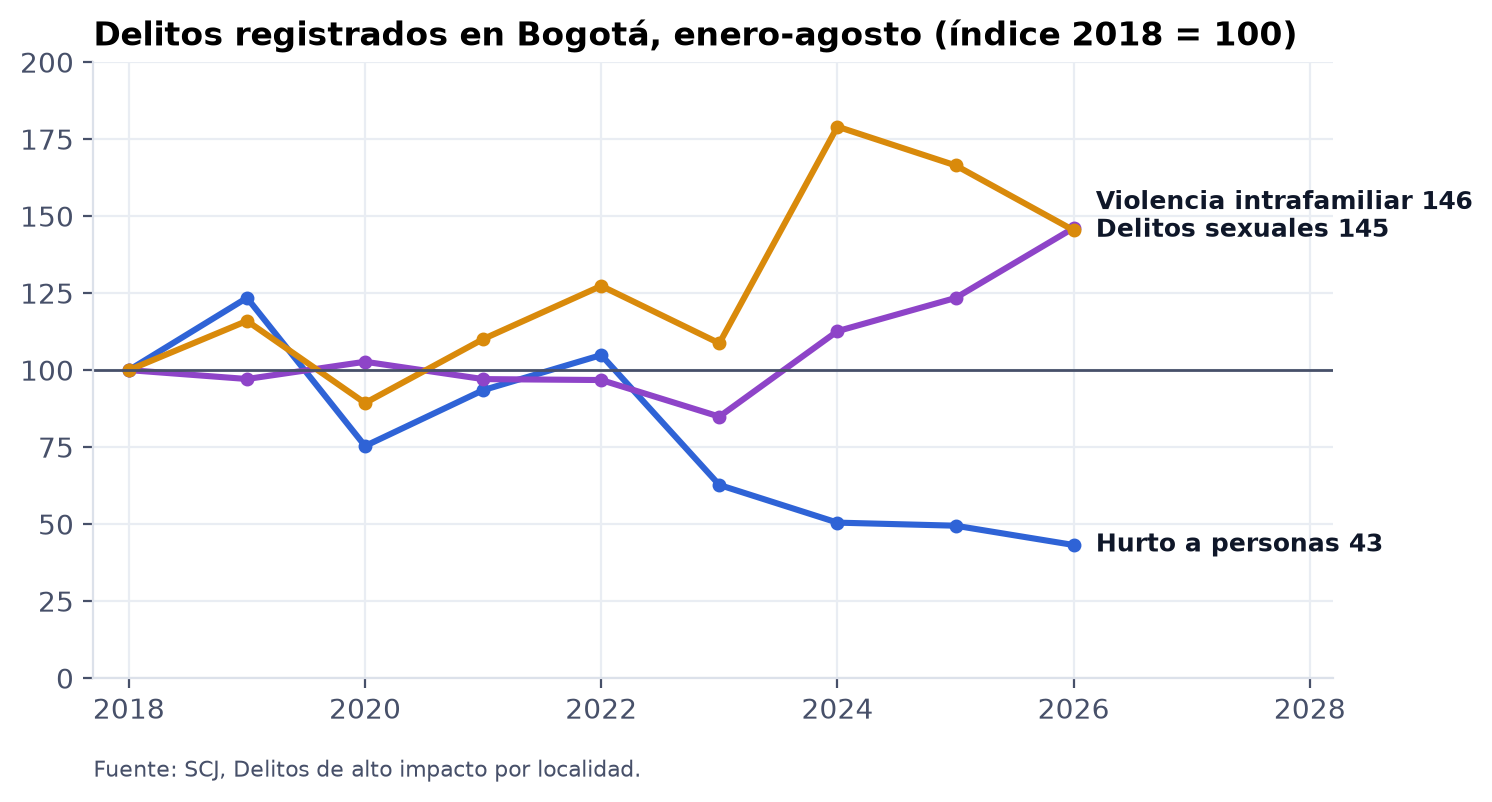

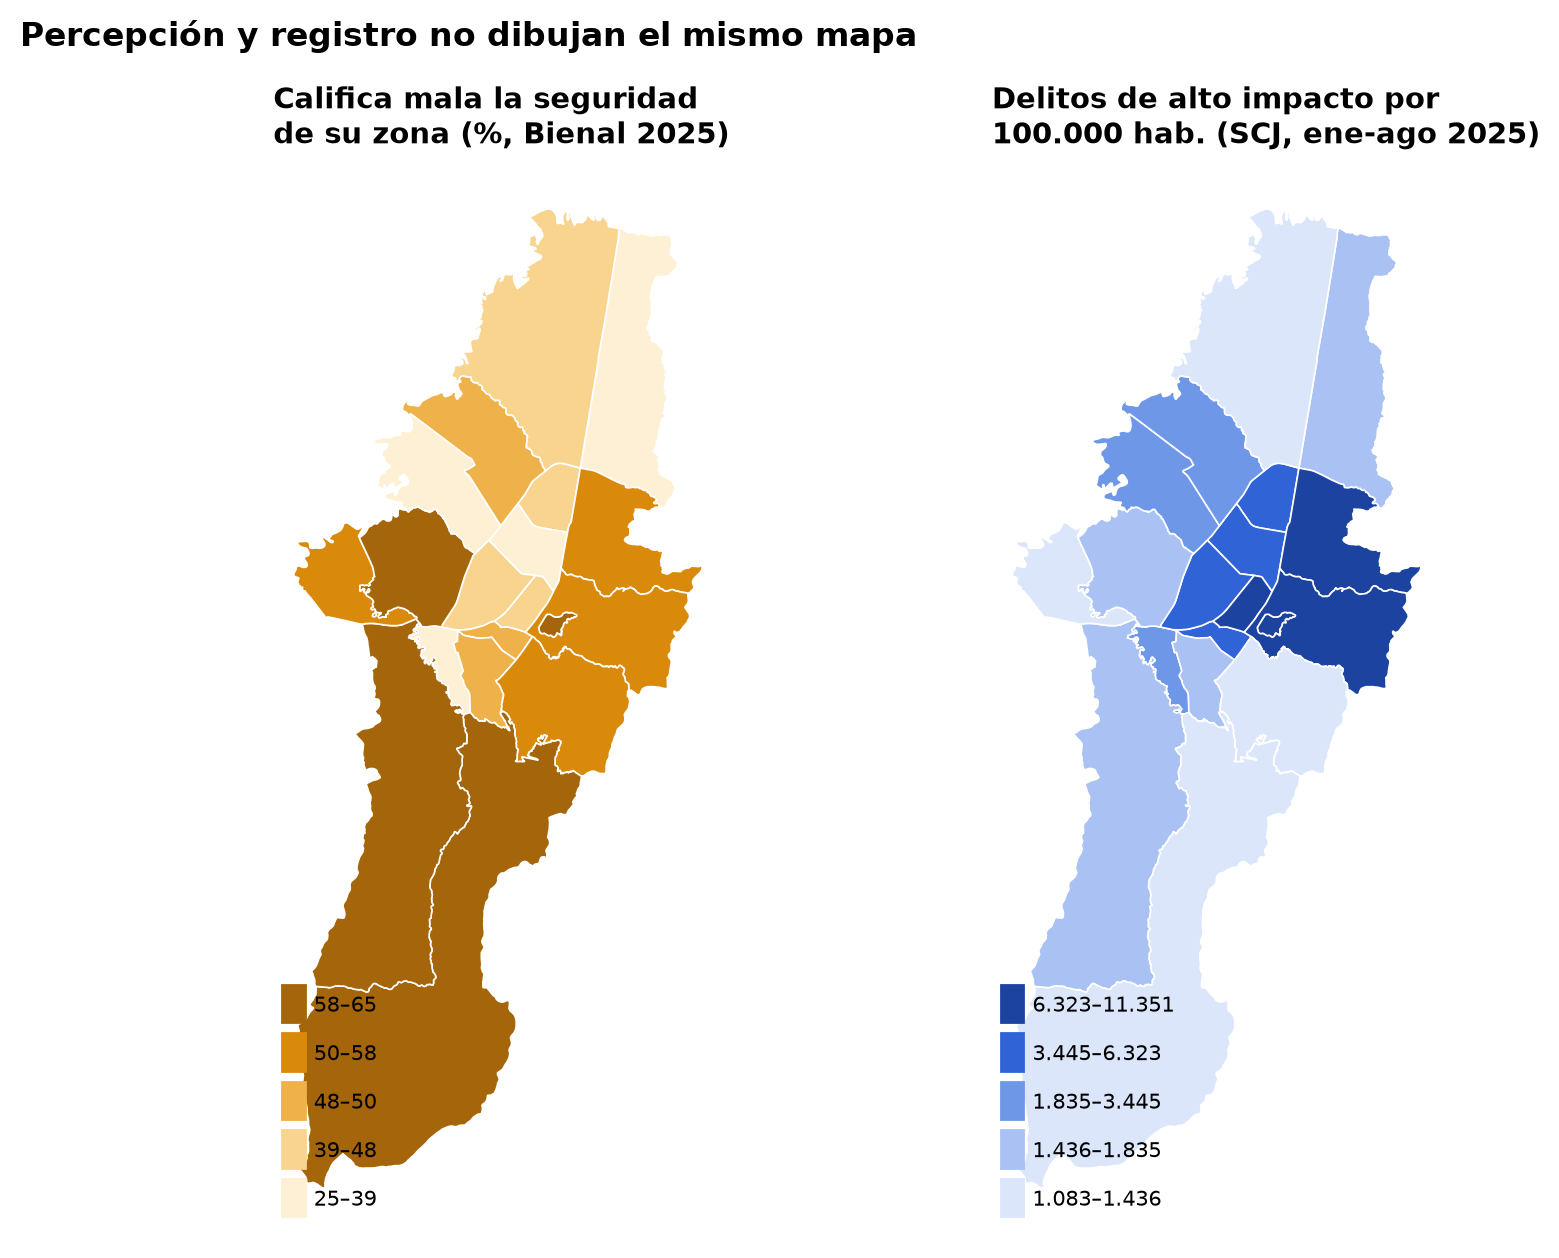

In [10]:
s = delitos.groupby(["codigo", "anio"]).casos.sum().unstack()
cambio = lambda c, a, b: (s.loc[c, b] / s.loc[c, a] - 1) * 100
print(f"Hurto a personas 2019→2026: {cambio('HP', 2019, 2026):+.1f} %   | motos: {cambio('HM', 2019, 2026):+.1f} %   | residencias: {cambio('HR', 2019, 2026):+.1f} %")
print(f"Violencia intrafamiliar 2018→2026: {cambio('VI', 2018, 2026):+.1f} %   | delitos sexuales: {cambio('DS', 2018, 2026):+.1f} %")
print(f"Califican a Bogotá insegura: {w('ciudad_insegura'):.1f} %  | su zona: {w('zona_insegura'):.1f} %  | creen que está peor que el año pasado: {w('ciudad_peor_que_antes'):.1f} %")
display(Image(F.serie(delitos)))
display(Image(F.mapas(geo, P)))

## 6. Diagnóstico: ¿qué explica sentir insegura la zona? (H1)

**Modelo principal.** Logit ponderado con el factor de expansión de la Bienal. Resultado: califica mala o muy mala la seguridad de su zona. Variables: perfil (sexo, edad, estrato, arriendo), delito registrado de la localidad (hurtos y homicidios por 100.000, llamadas 123 por narcóticos) y hechos del entorno. Reportamos **efectos marginales promedio (AME)** en puntos porcentuales, con IC 95 % por **bootstrap de localidades** (con 19 conglomerados, los errores agrupados analíticos son optimistas).

n = 5538 | prevalencia ponderada = 48.4 %


,etiqueta,ame_pp,ic_inf,ic_sup,p
0,Ser mujer,-1.075,-4.638,3.350,0.611
1,Edad (por año),0.026,-0.159,0.183,0.802
2,Estrato (por nivel),-8.169,-10.491,-3.413,0.000
3,Vive en arriendo,1.752,-3.096,7.017,0.538
4,Hurtos en la localidad (+1.000 por 100 mil),-0.105,-5.610,1.740,0.927
5,Homicidios en la localidad (+1 por 100 mil),0.470,0.015,1.314,0.006
6,Llamadas 123 por narcóticos (+100 por 100 mil),-0.353,-1.958,2.030,0.549
7,Atracos en el parque más cercano,13.287,6.218,17.501,0.000
8,Venta o consumo de drogas en el parque,-2.871,-7.404,3.974,0.254
9,No tiene parque cerca,-6.880,-12.731,-2.642,0.008


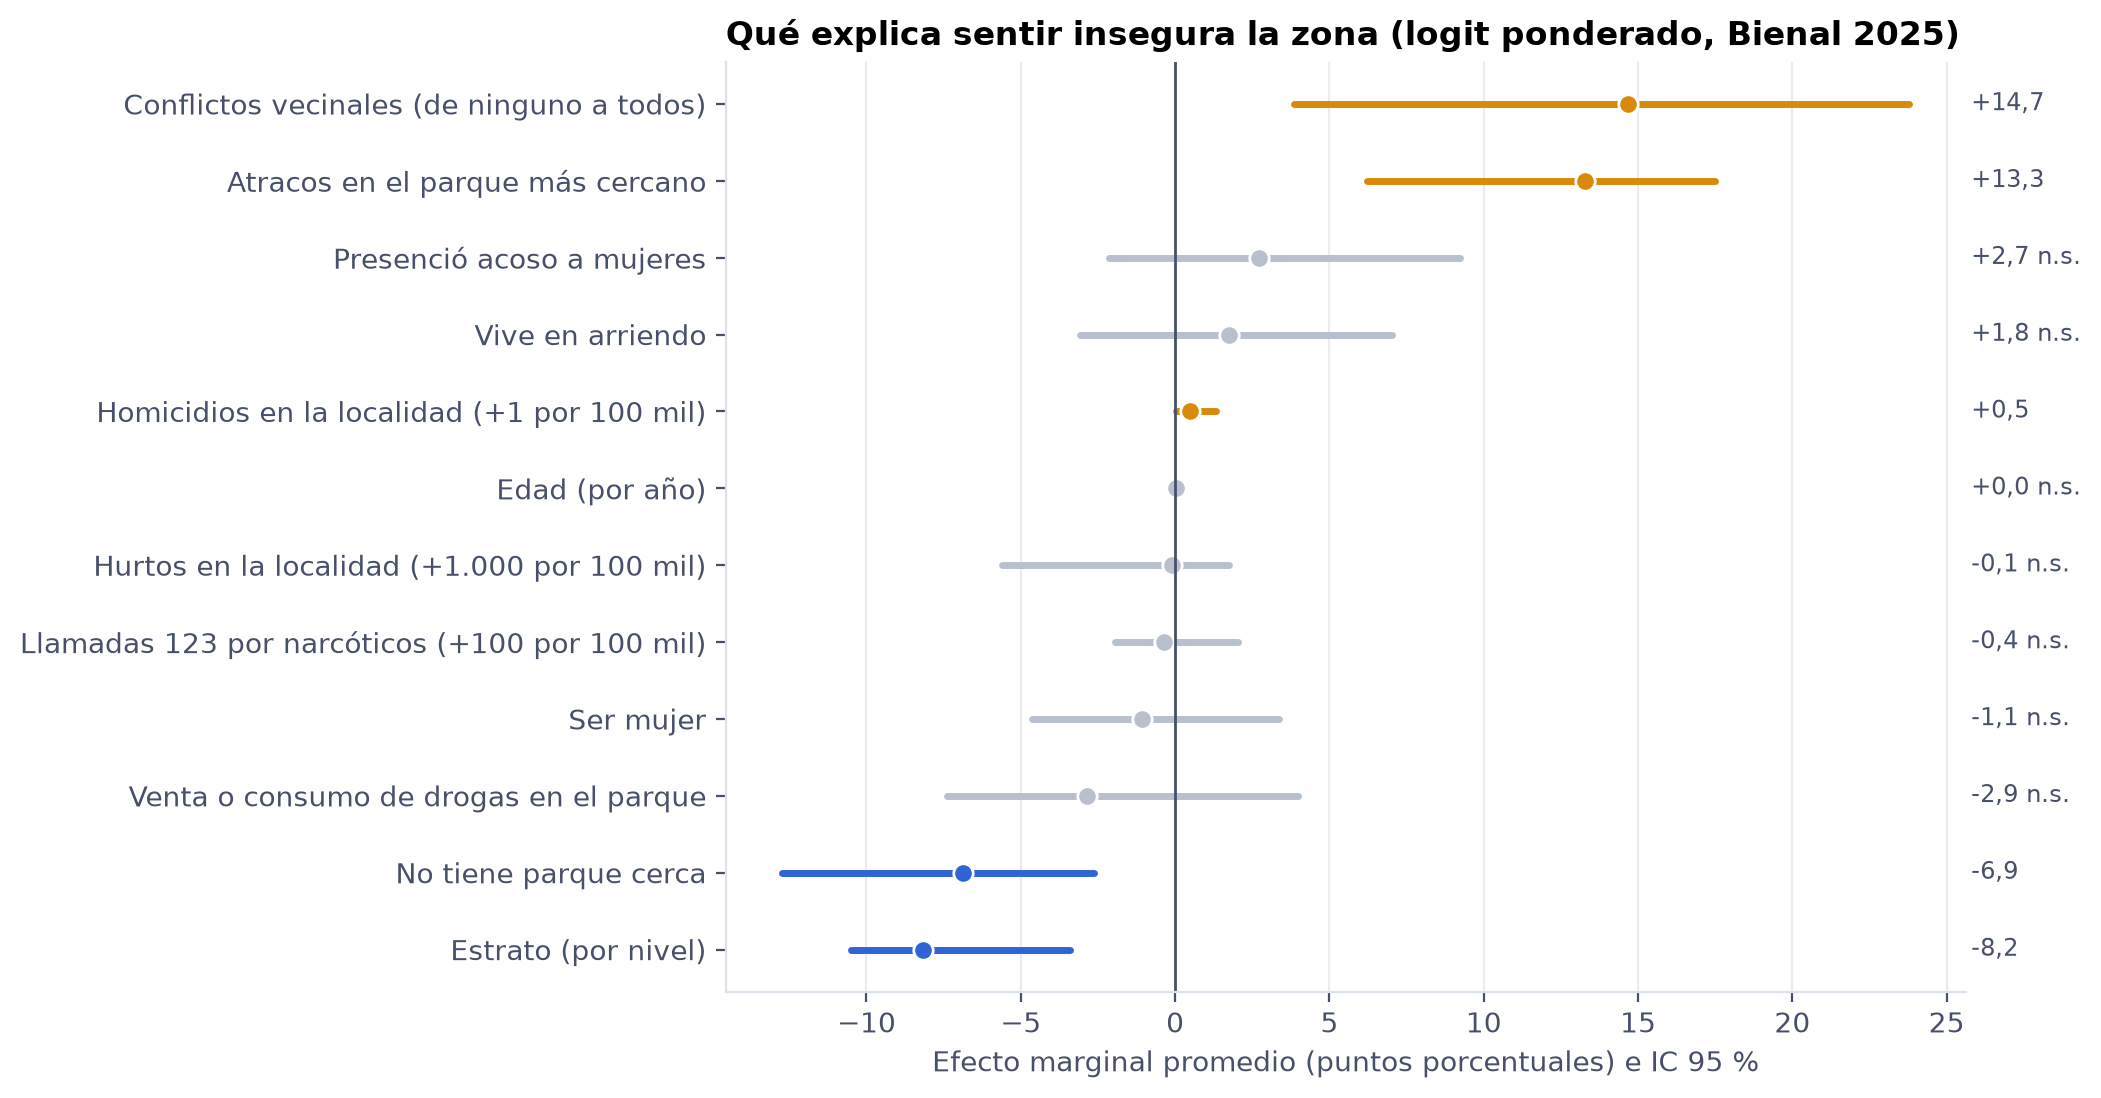

In [11]:
R = PL.modelar(P, eb, emv, n_boot=N_BOOT)
tabla = R["m_hechos"].assign(etiqueta=R["m_hechos"].variable.map(PL.ETIQUETAS))[["etiqueta", "ame_pp", "ic_inf", "ic_sup", "p"]]
print("n =", R["m_hechos"].attrs["n"], "| prevalencia ponderada =", f"{R['m_hechos'].attrs['media']*100:.1f} %")
display(tabla.round(3))
display(Image(F.efectos(R["m_hechos"], PL.ETIQUETAS)))

**Lectura.** Ver atracos en el parque más cercano y vivir con conflictos vecinales elevan con fuerza la probabilidad de sentir insegura la zona. El **hurto registrado de la localidad no tiene efecto**; el homicidio sí, pero pequeño (por cada homicidio adicional por 100.000 habitantes). El estrato alto protege.

**Modelo complementario (con calificaciones del entorno).** Alumbrado y ventas informales se califican en la misma batería que la seguridad de la zona; su efecto puede estar inflado por el juicio general de la persona (sesgo de método común). Los reportamos aparte.

In [12]:
display(R['m_calif'].assign(etiqueta=R['m_calif'].variable.map(PL.ETIQUETAS))[['etiqueta','ame_pp','ic_inf','ic_sup','p']].round(3))

,etiqueta,ame_pp,ic_inf,ic_sup,p
0,Ser mujer,-1.388,-4.671,2.246,0.444
1,Edad (por año),0.055,-0.084,0.161,0.482
2,Estrato (por nivel),-5.779,-7.088,-2.353,0.000
3,Vive en arriendo,1.307,-1.959,5.129,0.487
4,Hurtos en la localidad (+1.000 por 100 mil),-0.981,-6.973,1.381,0.463
5,Homicidios en la localidad (+1 por 100 mil),0.316,-0.107,1.440,0.117
6,Llamadas 123 por narcóticos (+100 por 100 mil),0.505,-1.374,3.033,0.485
7,Atracos en el parque más cercano,10.151,4.052,14.317,0.000
8,Venta o consumo de drogas en el parque,0.471,-1.854,3.955,0.736
9,No tiene parque cerca,-13.052,-17.583,-8.851,0.000


### 6.1 Robustez
- **Efectos fijos de localidad:** compara personas dentro de la misma localidad (el delito de la localidad queda absorbido).
- **Modelo lineal ponderado con wild cluster bootstrap** (pesos de Webb, 999 réplicas): p-valores correctos con pocos conglomerados.
- **Otros resultados:** califica a Bogotá como insegura; siente miedo en el espacio público.

In [13]:
fe = R["m_efectos_fijos"]; fe = fe[~fe.variable.str.startswith("loc_")]
display(fe.assign(etiqueta=fe.variable.map(PL.ETIQUETAS))[["etiqueta", "ame_pp", "ic_inf", "ic_sup", "p"]].round(3))
display(R["lpm_wild"].assign(etiqueta=R["lpm_wild"].variable.map(PL.ETIQUETAS)).round(3))
for k in ("m_ciudad", "m_miedo"):
    print(k, "| prevalencia:", f"{R[k].attrs['media']*100:.1f} %")
    display(R[k][R[k].p < 0.05].assign(etiqueta=lambda d: d.variable.map(PL.ETIQUETAS))[["etiqueta", "ame_pp", "ic_inf", "ic_sup", "p"]].round(3))

,etiqueta,ame_pp,ic_inf,ic_sup,p
0,Ser mujer,-0.829,-4.521,3.304,0.695
1,Edad (por año),0.031,-0.140,0.156,0.754
2,Estrato (por nivel),-4.246,-8.251,-0.464,0.047
3,Vive en arriendo,2.714,-1.974,6.761,0.329
4,Atracos en el parque más cercano,12.333,5.914,15.863,0.000
5,Venta o consumo de drogas en el parque,-2.802,-7.758,4.445,0.335
6,No tiene parque cerca,-7.063,-11.322,-2.957,0.004
7,Presenció acoso a mujeres,3.250,-2.188,9.380,0.289
8,Conflictos vecinales (de ninguno a todos),15.428,5.301,24.989,0.012


,variable,coef_pp,p_cluster,p_wild,etiqueta
0,hurtos_100k_miles,-0.127,0.913,0.919,Hurtos en la localidad (+1.000 por 100 mil)
1,homicidios_100k,0.472,0.005,0.033,Homicidios en la localidad (+1 por 100 mil)
2,narcoticos_100k_cientos,-0.367,0.525,0.543,Llamadas 123 por narcóticos (+100 por 100 mil)
3,parque_atracos,13.290,0.000,0.000,Atracos en el parque más cercano
4,conflictos_vecinos,15.044,0.007,0.046,Conflictos vecinales (de ninguno a todos)


m_ciudad | prevalencia: 74.0 %


,etiqueta,ame_pp,ic_inf,ic_sup,p
0,Ser mujer,3.409,0.188,5.431,0.039
5,Homicidios en la localidad (+1 por 100 mil),-0.543,-1.206,0.315,0.014


m_miedo | prevalencia: 10.8 %


,etiqueta,ame_pp,ic_inf,ic_sup,p
0,Ser mujer,3.863,1.941,5.715,0.000
8,Venta o consumo de drogas en el parque,4.326,2.967,6.347,0.000


## 7. Predictivo: ¿qué bloque de variables anticipa mejor la percepción?

AUC fuera de muestra con validación cruzada estratificada (5 pliegues × 5 repeticiones), ponderada. Si el delito registrado explicara la percepción, agregarlo debería mejorar la predicción.

,bloque,auc,auc_sd
0,"Perfil (sexo, edad, estrato, tenencia)",0.609,0.023
1,Perfil + delito registrado,0.611,0.021
2,Perfil + hechos del entorno,0.655,0.024
3,Perfil + hechos + delito,0.656,0.023
4,Perfil + calificación del entorno,0.755,0.016
5,Todo,0.782,0.017


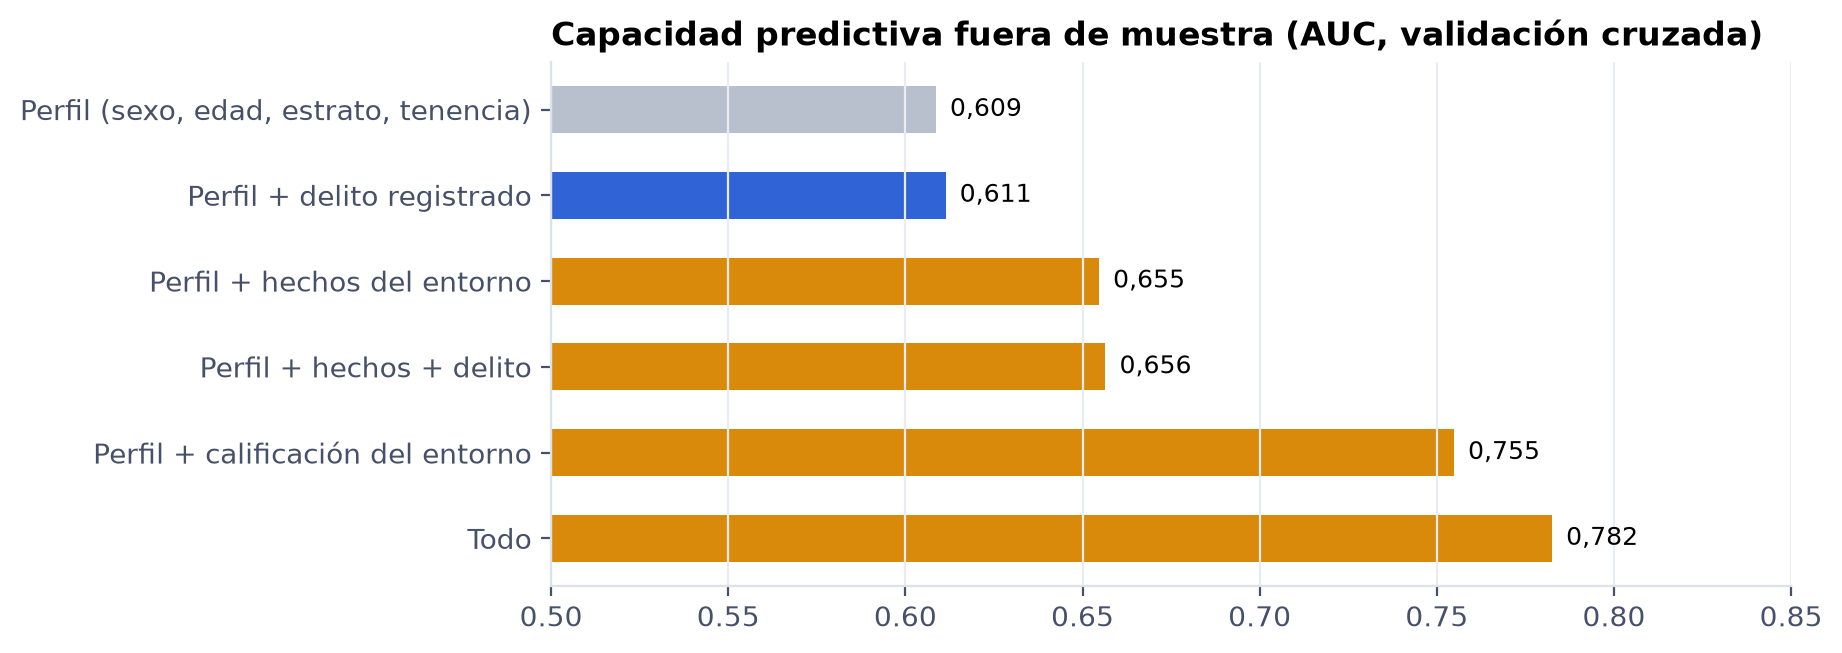

In [14]:
display(R["auc"][["bloque", "auc", "auc_sd"]].round(3))
display(Image(F.auc(R["auc"])))

## 8. Enfoque de género (H3)

Encuesta Mundial de Valores: logit ponderado con sexo, edad, estrato y **haber sido víctima** como controles. Así comparamos mujeres y hombres con la misma experiencia de victimización.

teme_acoso_sexual


,variable,ame_pp,ic_inf,ic_sup,p
0,mujer,18.020,12.883,23.432,0.000
1,edad,-0.319,-0.456,-0.177,0.000
2,estrato,0.400,-2.046,1.966,0.664
3,victima,2.695,-1.694,8.292,0.311


no_sale_noche


,variable,ame_pp,ic_inf,ic_sup,p
0,mujer,6.468,0.960,11.504,0.024
1,edad,-0.008,-0.145,0.146,0.918
2,estrato,1.506,-0.011,3.904,0.121
3,victima,2.452,-2.961,7.600,0.340


barrio_inseguro


,variable,ame_pp,ic_inf,ic_sup,p
0,mujer,9.281,5.049,13.892,0.000
1,edad,0.498,0.363,0.671,0.000
2,estrato,-5.102,-7.694,-3.526,0.000
3,victima,19.499,12.815,24.970,0.000


,mujeres,hombres
victima,20.600,28.400
no_sale_noche,63.500,57.200
teme_acoso_sexual,71.900,53.900
barrio_inseguro,59.200,51.800


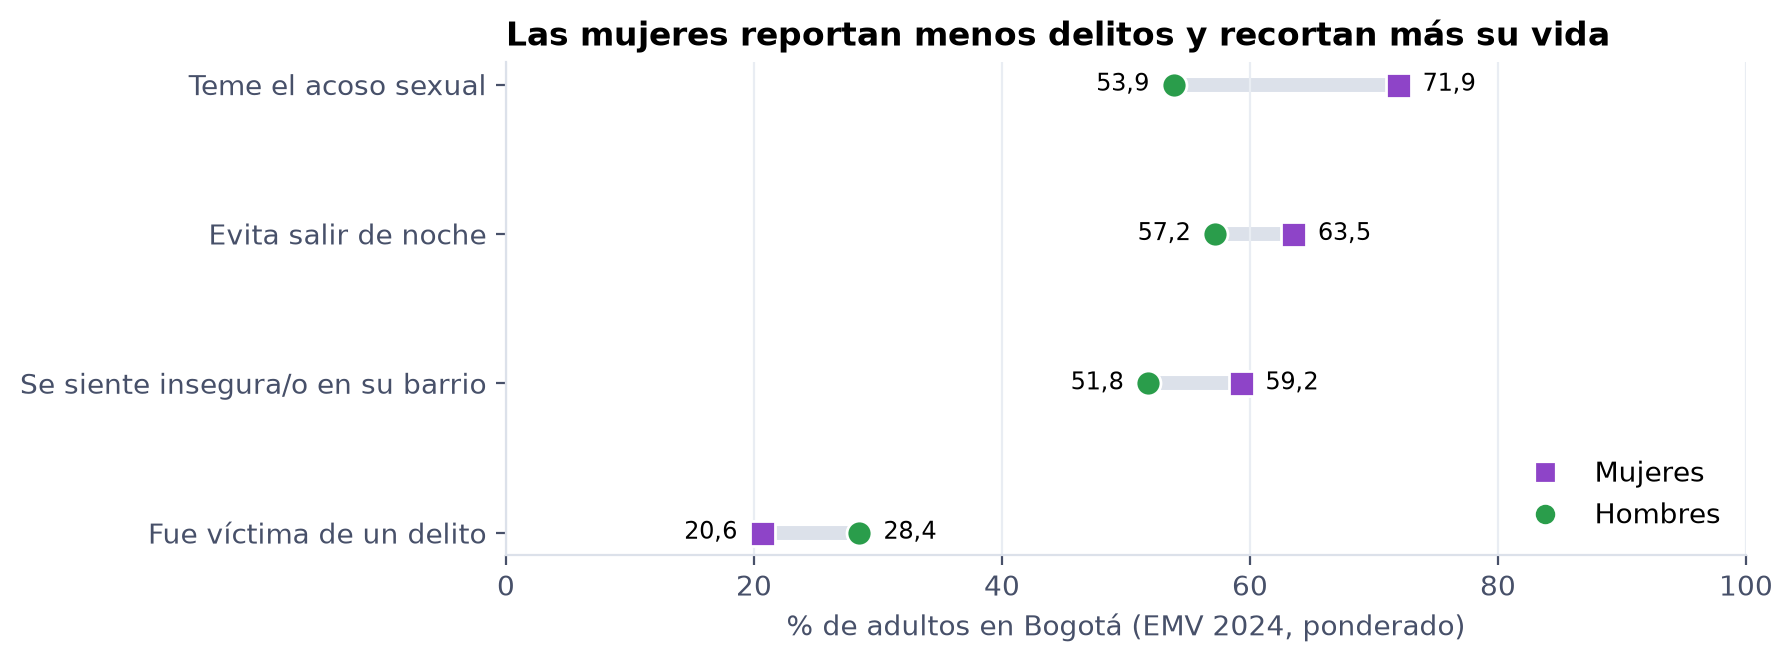

In [15]:
for y in ("teme_acoso_sexual", "no_sale_noche", "barrio_inseguro"):
    print(y); display(R[f"emv_{y}"][["variable", "ame_pp", "ic_inf", "ic_sup", "p"]].round(3))
por_sexo = {c: {s: np.average(emv[emv.mujer == v][c], weights=emv[emv.mujer == v].peso) * 100 for s, v in (("mujeres", 1.0), ("hombres", 0.0))}
            for c in ["victima", "no_sale_noche", "teme_acoso_sexual", "barrio_inseguro"]}
display(pd.DataFrame(por_sexo).T.round(1))
display(Image(F.genero(por_sexo)))

## 9. Territorio: validaciones, cifra oculta e Índice de Brecha (H2)

**Validaciones.** Contrastamos percepción y registro entre las 19 localidades (Spearman con IC bootstrap y corrección de Benjamini-Hochberg por pruebas múltiples).

**Cifra oculta.** Adultos que dicen haber sido víctimas en el último año (EMV 2024 × población adulta SDP) por cada delito de alto impacto registrado en 2024 (enero-agosto llevado a 12 meses). Personas y hechos no son la misma unidad: es un orden de magnitud.

**Índice de Brecha de Seguridad (IBS)** = z(% zona insegura) − z(ln delitos de alto impacto por 100.000). Intervalos por bootstrap ponderado dentro de cada localidad (1.000 réplicas).

,prueba,rho,p,ic_inf,ic_sup,n,p_bh
0,Drogas en el parque (Bienal) vs incidentes por...,-0.084,0.732,-0.569,0.402,19,0.854
1,Zona insegura (Bienal) vs riñas 123,0.225,0.355,-0.330,0.664,19,0.622
2,Alumbrado malo (Bienal) vs luminarias por km² ...,-0.111,0.652,-0.593,0.429,19,0.854
3,Víctimas (EMV) vs delitos registrados (SCJ),0.026,0.915,-0.492,0.504,19,0.915
4,Zona insegura (Bienal) vs delitos registrados ...,-0.249,0.304,-0.692,0.300,19,0.622
5,Barrio inseguro (EMV) vs zona insegura (Bienal),0.346,0.147,-0.205,0.765,19,0.515
6,Índice de Brecha vs cifra oculta (víctimas por...,0.716,0.001,0.412,0.876,19,0.004


Bogotá: 5.6 víctimas por delito registrado


,nombre,emv_victima,victimas_estimadas,delitos_registrados,razon,razon_inf,razon_sup
6,Bosa,26.500,"150,816.200","14,161.500",10.600,7.000,14.300
7,Kennedy,30.500,"257,172.700","28,269.000",9.100,6.300,11.900
3,San Cristóbal,25.600,"78,317.000","8,746.500",9.000,5.900,12.100
10,Suba,23.700,"236,123.400","28,713.000",8.200,5.200,11.300
5,Tunjuelito,29.300,"40,897.600","5,086.500",8.000,5.500,10.600
4,Usme,19.500,"57,411.900","7,578.000",7.600,4.400,10.800
17,Rafael Uribe Uribe,22.600,"66,499.900","9,136.500",7.300,4.500,10.000
18,Ciudad Bolívar,22.500,"111,394.900","16,015.500",7.000,4.300,9.600
9,Engativá,23.600,"158,545.000","25,215.000",6.300,4.000,8.600
0,Usaquén,18.000,"85,439.900","16,792.500",5.100,2.700,7.400


,nombre,ibs,ibs_p05,ibs_p95,puesto,prob_top5
4,Usme,2.670,2.230,2.980,1,1.000
18,Ciudad Bolívar,2.340,1.940,2.610,2,1.000
6,Bosa,1.970,1.490,2.390,3,1.000
7,Kennedy,1.720,1.290,2.080,4,0.980
3,San Cristóbal,1.540,1.000,2.020,5,0.910
17,Rafael Uribe Uribe,0.910,0.420,1.380,6,0.110
9,Engativá,0.500,0.180,0.820,7,0.000
10,Suba,0.230,-0.060,0.590,8,0.000
14,Antonio Nariño,-0.310,-0.780,0.130,9,0.000
2,Santa Fe,-0.390,-0.990,0.100,10,0.000


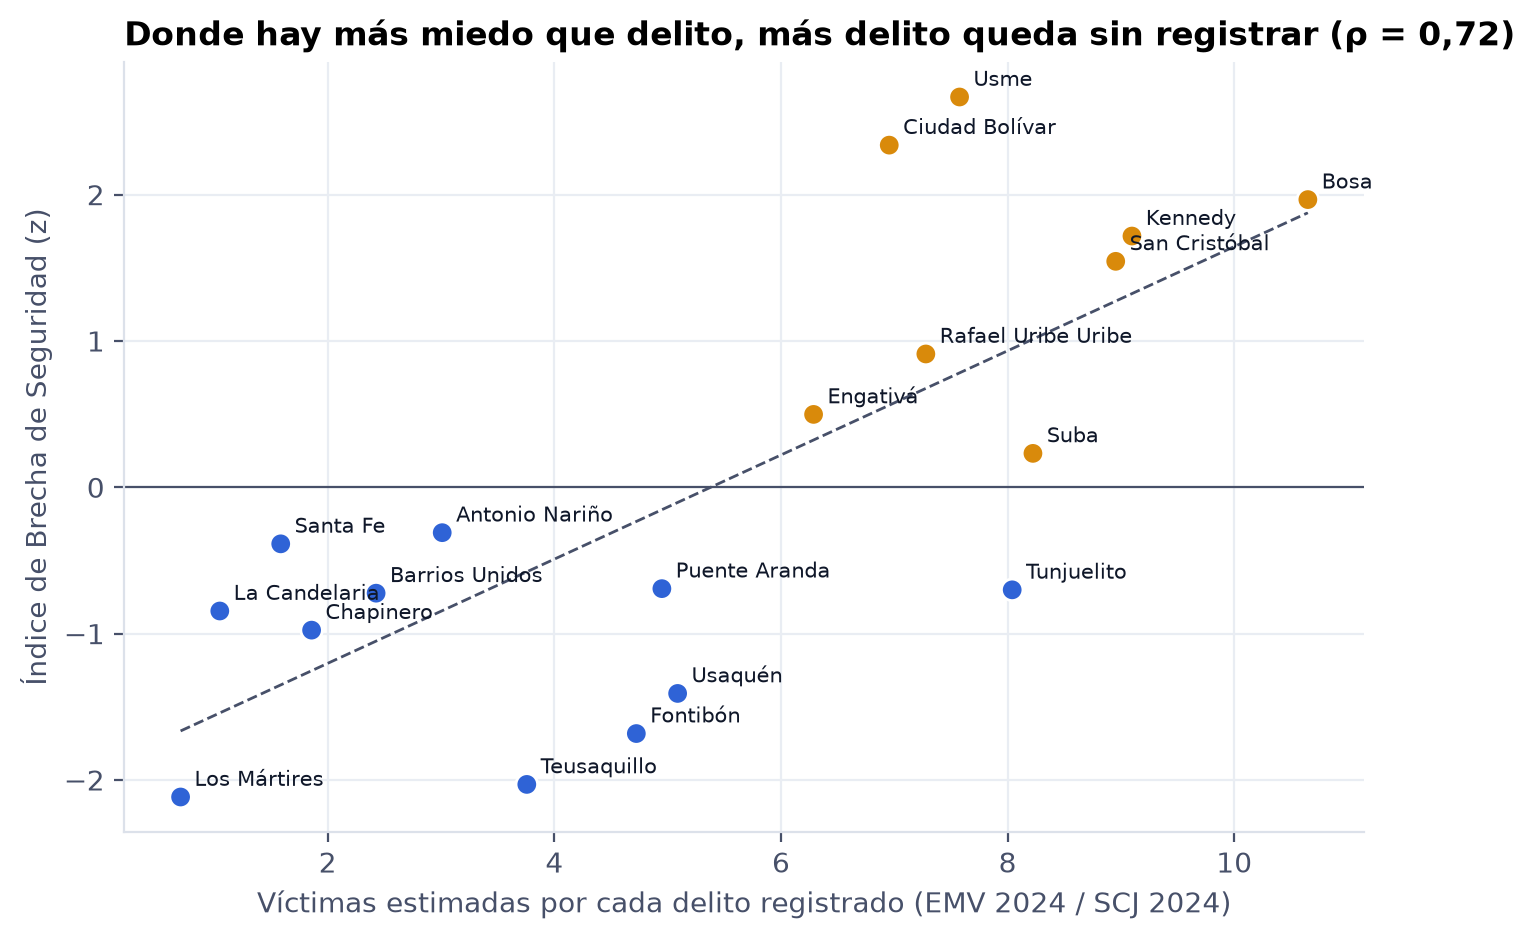

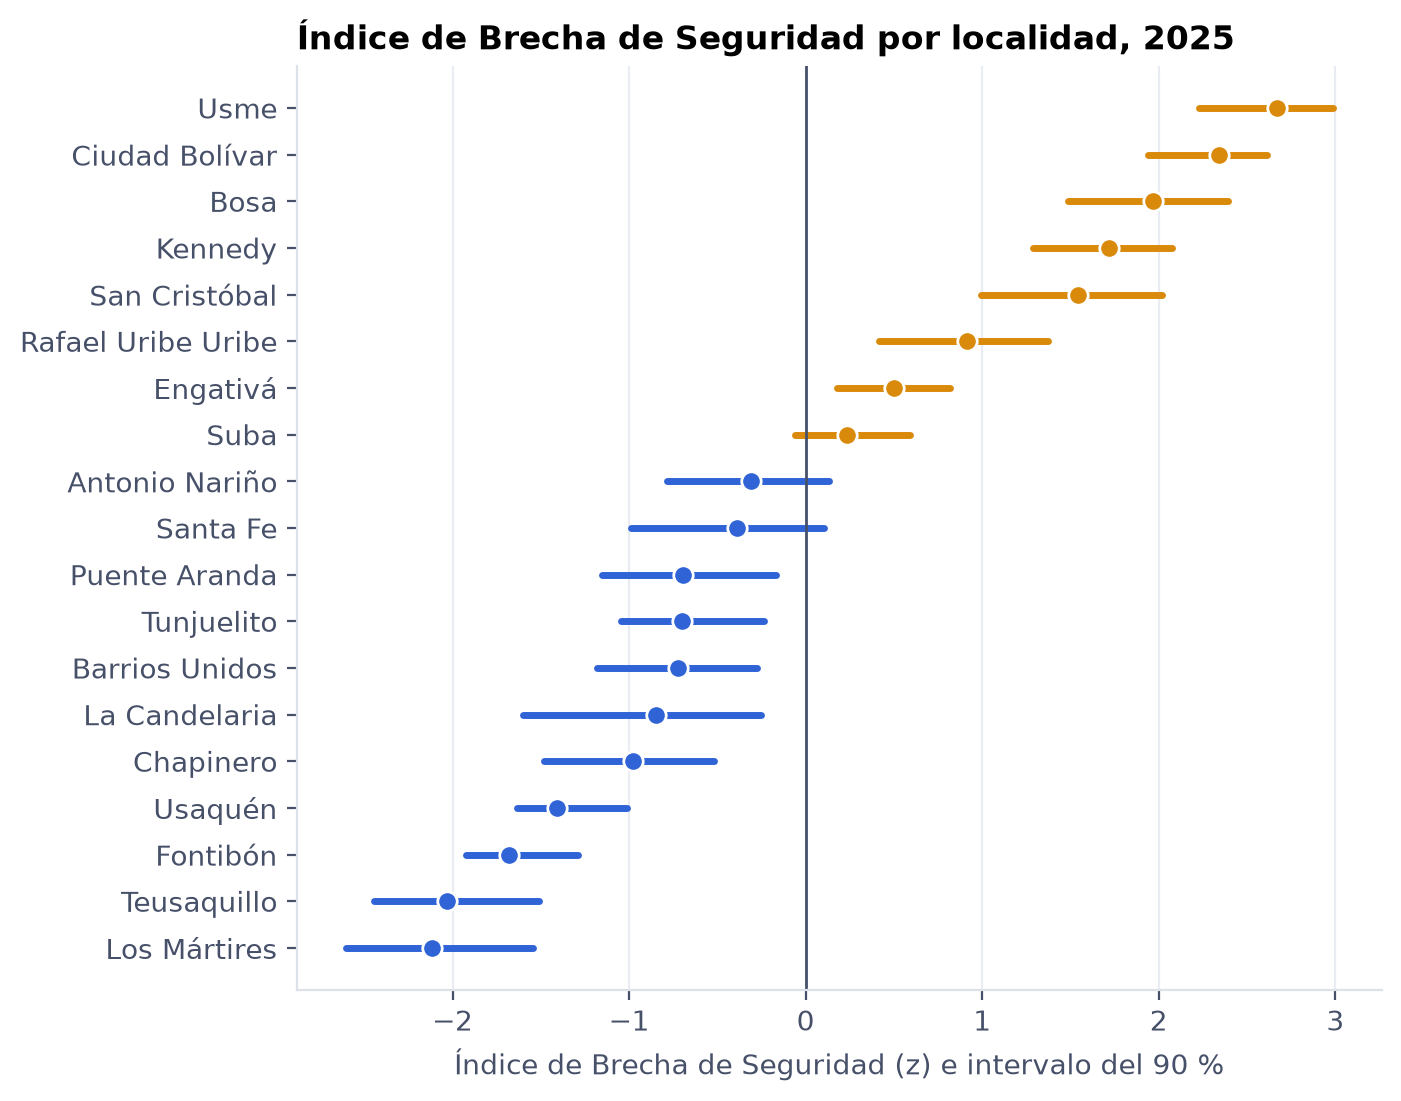

In [16]:
T = PL.territorio(P, eb, t)
display(T["validaciones"].round(3))
co = T["cifra_oculta"]
print(f"Bogotá: {co.victimas_estimadas.sum()/co.delitos_registrados.sum():.1f} víctimas por delito registrado")
display(co[["nombre", "emv_victima", "victimas_estimadas", "delitos_registrados", "razon", "razon_inf", "razon_sup"]].sort_values("razon", ascending=False).round(1))
ibs = T["ibs"].assign(nombre=T["ibs"].localidad.map(LOCALIDADES))
display(ibs[["nombre", "ibs", "ibs_p05", "ibs_p95", "puesto", "prob_top5"]].round(2))
rho = T["validaciones"].iloc[-1]["rho"]
display(Image(F.brecha_cifra(T["ibs"], co, rho)))
display(Image(F.ranking_ibs(T["ibs"])))

**Lectura.** Seis de las siete relaciones territoriales son nulas: el registro administrativo no refleja ni la percepción ni la victimización. La única que sobrevive a la corrección es la central: **el Índice de Brecha crece donde más delito queda sin registrar**. Parte del miedo «sobrante» de la periferia (Usme, Ciudad Bolívar, Bosa, Kennedy, San Cristóbal) es delito real que no llega a las cifras. En el centro (La Candelaria, Los Mártires) la tasa por residente se infla con población flotante.

## 10. Prescriptivo: escenarios de intervención

Evaluamos el modelo (hechos del entorno + alumbrado) en cuatro escenarios extremos por localidad: situación actual, alumbrado resuelto, parques sin atracos y ambos. El visor interpola coberturas intermedias. Es una **sensibilidad del modelo** para comparar territorios, no un efecto causal: un piloto con línea base y grupo de comparación lo confirmaría.

In [17]:
esc = R["escenarios"]
e = esc[esc.grupo == "total"].assign(nombre=lambda d: d.localidad.map(LOCALIDADES).fillna("Bogotá"))
e = e.assign(cambio_alumbrado=e.p10 - e.p00, cambio_parques=e.p01 - e.p00, cambio_ambos=e.p11 - e.p00)
display(e[["nombre", "observado", "p00", "cambio_alumbrado", "cambio_parques", "cambio_ambos"]].sort_values("cambio_ambos").round(1))

,nombre,observado,p00,cambio_alumbrado,cambio_parques,cambio_ambos
16,La Candelaria,61.000,49.600,-19.100,-4.200,-23.400
5,Tunjuelito,36.000,50.700,-18.700,-2.700,-21.300
18,Ciudad Bolívar,65.400,66.800,-15.400,-4.500,-21.000
2,Santa Fe,58.100,64.500,-14.800,-3.100,-18.700
4,Usme,64.600,56.900,-14.400,-3.600,-18.700
13,Los Mártires,39.700,52.300,-14.600,-3.500,-18.400
6,Bosa,57.100,56.000,-13.100,-4.400,-17.700
7,Kennedy,58.400,49.100,-13.300,-2.900,-16.200
9,Engativá,49.400,47.300,-9.500,-5.400,-15.000
19,Bogotá,48.400,48.400,-10.900,-3.800,-14.900


## 11. Indicador propuesto (regla 10.II: medible, comparable, consistente)

| Campo | Definición |
|---|---|
| Nombre | Índice de Brecha de Seguridad (IBS) |
| Fórmula | z(% de adultos que califican mala o muy mala la seguridad de su zona) − z(ln delitos de alto impacto por 100.000 hab.) |
| Fuentes | Percepción: Encuesta Distrital de Percepción (SDP) o Bienal de Cultura Ciudadana (SCRD). Delito: SCJ. Población: SDP |
| Periodicidad | Semestral por sector de UPL y anual por localidad y UPL (representatividad de la EDP) |
| Desagregación | Localidad, UPL, sexo, edad, estrato |
| Línea base | 2025 (tabla de la sección 9) |
| Acompañantes | Víctimas por delito registrado (cifra oculta); % de mujeres que evita salir de noche |
| Meta sugerida | IBS menor a +1 en las cinco localidades priorizadas y menor cifra oculta en la periferia |

## 12. Limitaciones

1. **Asociación, no causalidad.** Controlamos perfil y territorio, pero no hay asignación aleatoria.
2. **Sesgo de método común** en las calificaciones de la batería P66 (alumbrado, ventas informales): por eso el modelo principal usa solo hechos de otras preguntas.
3. **Validación objetiva del alumbrado imposible:** el inventario de la UAESP en el portal es de agosto de 2019 y por localidad (ρ con la percepción ≈ 0).
4. **EMV:** 96 encuestas por localidad (±10 pp), factor de ponderación nacional; localidad recuperada del tablero oficial.
5. **Delitos solo por localidad** en datos abiertos; la Encuesta Distrital de Percepción 2025 no se pudo descargar en forma automatizada (el sitio de la SDP corta las conexiones automáticas).
6. Sumapaz (rural) se excluye; los mapas muestran la huella urbana.

## 13. Exportes: resultados, visor web, descargas y Power BI

In [18]:
S = PL.resumen(t, P, eb, R, T)
(RAIZ / "outputs" / "resultados.json").write_text(json.dumps(S, ensure_ascii=False, indent=1), encoding="utf-8")
PL.guardar(t, P, eb, iu, R, T)
res = {"t": t, "P": P, "eb": eb, "iu": iu, "R": R, "T": T, "S": S}
print(EX.visor(res, PL.ETIQUETAS))
print(sorted(p.name for p in (RAIZ / "visor" / "public" / "descargas").iterdir()))
print(sorted(p.name for p in (RAIZ / "powerbi" / "datos").iterdir()))

C:\Users\rafal\OneDrive\Desktop\Projects\datajam-miedo-que-no-baja\visor\data\visor.json
['cifra_oculta_localidad.csv', 'efectos_marginales_modelo_principal.csv', 'incidentes_123_upz_2025.csv', 'indice_brecha_seguridad.csv', 'localidades_brecha_seguridad.geojson', 'panel_localidad_2025.csv', 'serie_delitos_bogota_ene_ago.csv', 'upz_incidentes_123.geojson']
['dim_localidad_indicadores.csv', 'fact_auc_bloques.csv', 'fact_delitos_serie.csv', 'fact_efectos_marginales.csv', 'fact_genero_emv.csv']


## 14. Conclusiones y recomendaciones

1. **La ciudad no ve buena parte de su delito.** Hay unas 5,6 víctimas por cada delito de alto impacto registrado, y la razón llega a 10 en la periferia. La brecha entre miedo y registro va donde va el subregistro (ρ ≈ 0,72, la única relación que sobrevive a la corrección). → **Medir la seguridad con victimización** (preguntas de la EDP por UPL) y corregir la asignación de recursos donde el registro subestima.
2. **El barrio se siente por lo que pasa en él.** Atracos en el parque cercano (+13 pp) y conflictos vecinales (+15 pp) pesan; el hurto registrado no (wild bootstrap p ≈ 0,9) y no mejora la predicción. → **Entornos que se sienten seguros**: parques sin atracos, mediación de conflictos y alumbrado, priorizados con el Índice de Brecha.
3. **Las mujeres pagan con autonomía.** A igual victimización, +18 pp de temor al acoso sexual y +6,5 pp de evitar salir de noche. → Adoptar **«evita salir de noche, por sexo»** como indicador de resultado de la política de seguridad.
4. **Datos para evaluar.** Publicar el inventario georreferenciado de alumbrado (el del portal es de 2019) y los delitos por UPZ.